In [1]:
!curl -L -o yolo26m-seg-hand.pt https://huggingface.co/NightingaleCen/YOLO26m-seg-hand/resolve/main/yolo26m-seg-hand.pt

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  1052  100  1052    0     0   5683      0 --:--:-- --:--:-- --:--:--  5717
100 51.9M  100 51.9M    0     0  20.7M      0  0:00:02  0:00:02 --:--:-- 25.0M


In [2]:
!curl -L -o ../models/yolo26m-seg-hand.pt https://huggingface.co/NightingaleCen/YOLO26m-seg-hand/resolve/main/yolo26m-seg-hand.pt
from ultralytics import YOLO

model = YOLO("../models/yolo26m-seg-hand.pt")
p = model.predict("../data/raw_data/A02_original_aslmnist/user_3/V9.jpg", save=True)
p

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  1054  100  1054    0     0   6323      0 --:--:-- --:--:-- --:--:--  6349
100 51.9M  100 51.9M    0     0  24.4M      0  0:00:02  0:00:02 --:--:-- 27.5M

image 1/1 /Users/delphinepessoa/code/notFonz/HandSpell/notebooks/../data/raw_data/A02_original_aslmnist/user_3/V9.jpg: 192x224 1 hand, 235.0ms
Speed: 5.8ms preprocess, 235.0ms inference, 14.2ms postprocess per image at shape (1, 3, 192, 224)
Results saved to /Users/delphinepessoa/code/notFonz/HandSpell/runs/segment/predict-8


[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: ultralytics.engine.results.Masks object
 names: {0: 'hand'}
 obb: None
 orig_img: array([[[ 86,  92,  87],
         [ 89,  95,  90],
         [ 89,  94,  92],
         ...,
         [ 23,  32,  45],
         [ 20,  29,  42],
         [ 17,  26,  39]],
 
        [[ 87,  93,  88],
         [ 90,  96,  91],
         [ 89,  94,  92],
         ...,
         [ 23,  32,  45],
         [ 17,  26,  39],
         [ 12,  21,  34]],
 
        [[ 89,  95,  90],
         [ 91,  97,  92],
         [ 90,  96,  91],
         ...,
         [ 23,  35,  47],
         [ 18,  27,  40],
         [ 11,  20,  33]],
 
        ...,
 
        [[136, 124, 112],
         [132, 121, 107],
         [135, 126, 112],
         ...,
         [114,  98,  86],
         [115,  99,  87],
         [115,  99,  87]],
 
        [[135, 124, 110],
         [135, 124, 110],
         [13

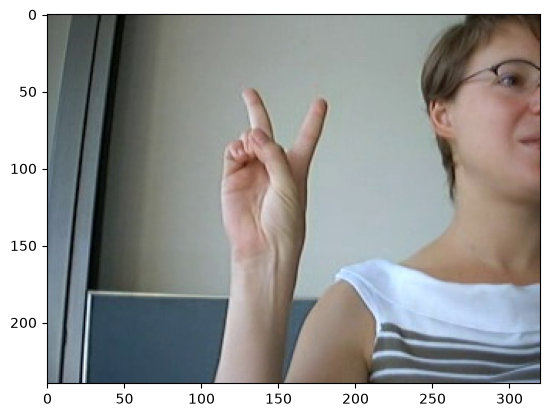

In [3]:
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle

fp = "../data/raw_data/A02_original_aslmnist/user_3/V9.jpg"
img = Image.open(fp, mode="r")
plt.imshow(img)

In [4]:
p[0].boxes.xyxy

tensor([[112.5246,  46.5700, 182.5884, 182.0104]])

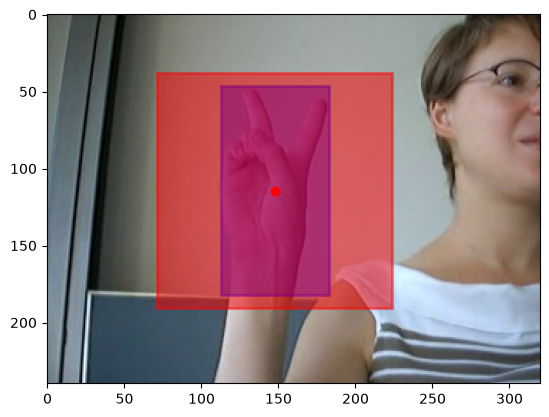

In [5]:
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle
import numpy as np

_, ax = plt.subplots(1,1)

# Load image
fp = "../data/raw_data/A02_original_aslmnist/user_3/V9.jpg"
img = Image.open(fp, mode="r")
plt.imshow(X=img)

# Hand segmentation prediction
x1, y1, x2, y2 = [float(el) for el in p[0].boxes.xyxy[0]]
origin_xy = p[0].boxes.xyxy[0][:2]
height = y2-y1
width = x2-x1
center_xy = np.array([(x1+x2)/2. , (y1+y2)/2.])

# Square transformation
diag = (height**2 + width**2)**0.5
orig_square_xy = center_xy - diag/2

# Plot shapes
ax.add_artist(Rectangle(origin_xy, width, height, fc="blue", ec="blue", lw=2, alpha=0.5))
ax.scatter([center_xy[0]], [center_xy[1]], c="r")
ax.add_artist(Rectangle(orig_square_xy, diag, diag, fc="red", ec="red", lw=2, alpha=0.5))


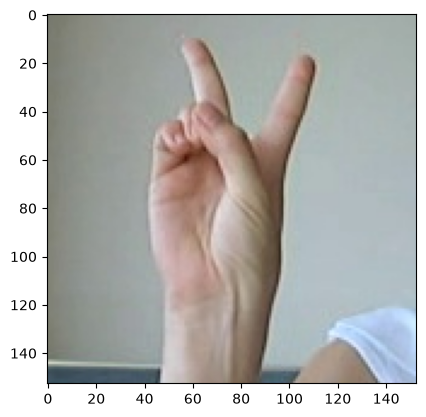

In [6]:
x_left = orig_square_xy[0]
y_up = orig_square_xy[1]
x_right = orig_square_xy[0] + diag
y_low = orig_square_xy[1] + diag
cropped_image = img.crop([x_left, y_up, x_right, y_low])
plt.imshow(cropped_image)

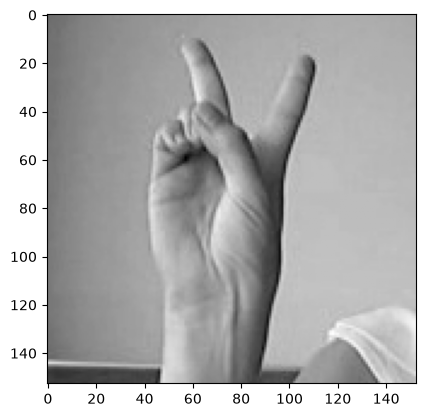

In [7]:
from skimage.color import rgb2gray
grey_image = rgb2gray(cropped_image)
plt.imshow(grey_image, cmap="gray")

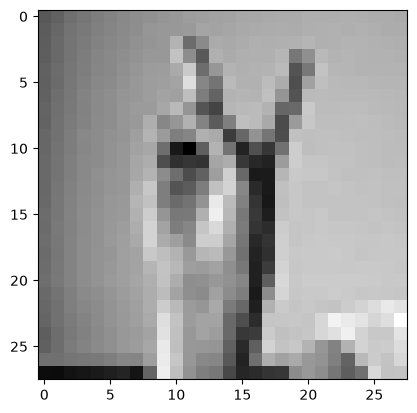

In [8]:
resized_img = cropped_image.resize((28,28), Image.LANCZOS)
grey_image = rgb2gray(resized_img)
plt.imshow(grey_image, cmap="gray")